Inter-Subject Correlation Matrix (Pearson r):
[[1.   0.79 0.68 0.81 0.75]
 [0.79 1.   0.52 0.86 0.78]
 [0.68 0.52 1.   0.61 0.62]
 [0.81 0.86 0.61 1.   0.82]
 [0.75 0.78 0.62 0.82 1.  ]]

Average ISC: 0.72


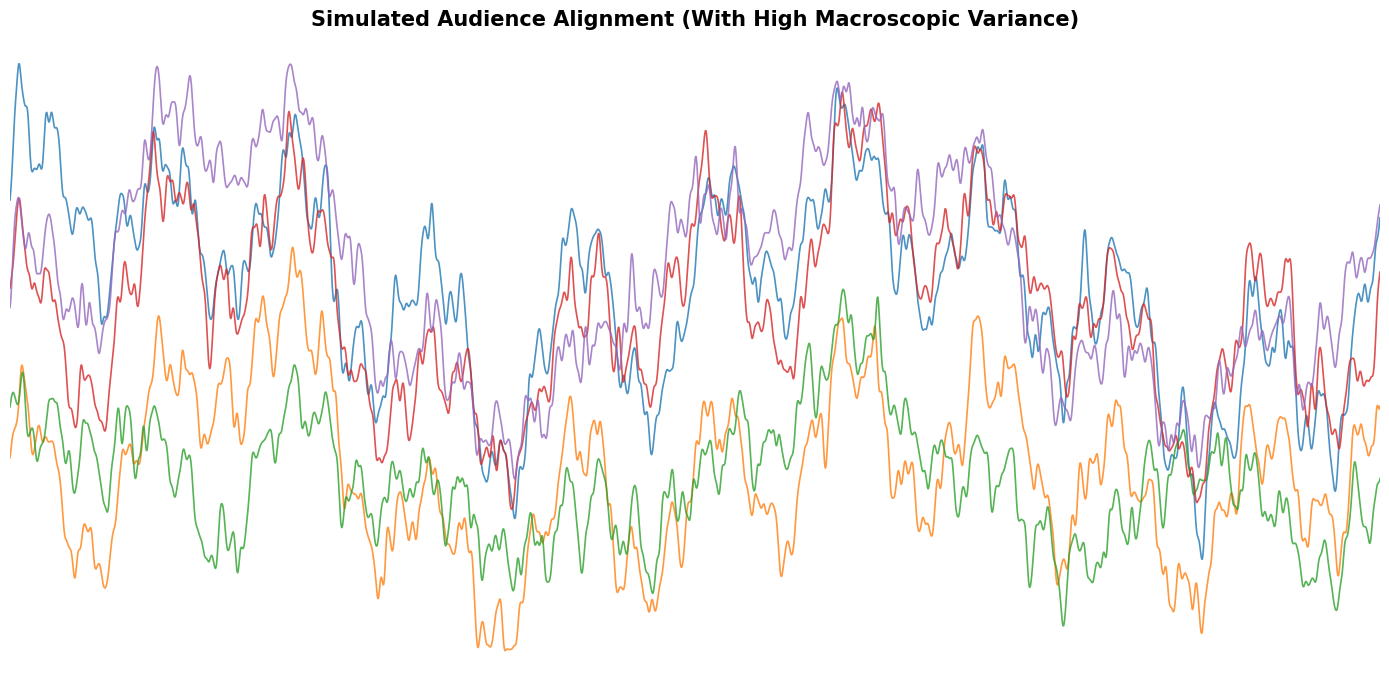

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Set seed for reproducible results
np.random.seed(42)

# --- 1. Parameters ---
duration_sec = 600  # 10 minutes
sampling_rate = 10  # 10 Hz
n_samples = duration_sec * sampling_rate
time = np.linspace(0, duration_sec, n_samples)
n_subjects = 5

# --- 2. Build the Base "Narrative" Components ---
# We keep the layers separate so we can apply individual weights later.
macro_arc = 1.5 * np.sin(2 * np.pi * time / 300)
scene_arc = 1.0 * np.sin(2 * np.pi * time / 60 + (np.pi/4))
beat_arc  = 0.5 * np.sin(2 * np.pi * time / 15)

signals = []

for i in range(n_subjects):
    # A. INDIVIDUAL RECEPTIVITY (Weighting)
    # Different people react differently to the structural levels of the message
    w_macro = np.random.uniform(0.4, 1.6)
    w_scene = np.random.uniform(0.4, 1.6)
    w_beat  = np.random.uniform(0.4, 1.6)
    
    # The shared signal, personalized for this specific receiver
    person_base = (macro_arc * w_macro) + (scene_arc * w_scene) + (beat_arc * w_beat)
    
    # B. INDIVIDUAL MACRO-WANDER (The "Overall Shape" variance)
    # This creates slow, sweeping biological changes unique to the person.
    # We use a very large sigma (150) to make it slow, and multiply by 15 
    # to restore the amplitude that gets crushed by heavy smoothing.
    slow_wander = gaussian_filter1d(np.random.randn(n_samples), sigma=150) * 15.0
    
    # C. INDIVIDUAL MICRO-NOISE (The "Local" variance)
    # Fast, twitchy physiological noise
    fast_noise = gaussian_filter1d(np.random.randn(n_samples), sigma=8) * 1.5
    
    # D. BASELINE OFFSET
    offset = np.random.uniform(-4.0, 4.0)
    
    # Combine everything into the final observed signal
    subject_signal = person_base + slow_wander + fast_noise + offset
    signals.append(subject_signal)

signals = np.array(signals)

# --- 3. Calculate and Print the Correlation Matrix ---
corr_matrix = np.corrcoef(signals)
print("Inter-Subject Correlation Matrix (Pearson r):")
print(np.round(corr_matrix, 2))
print(f"\nAverage ISC: {np.mean(corr_matrix[np.triu_indices(n_subjects, k=1)]):.2f}")

# --- 4. Plot the Results ---
plt.figure(figsize=(14, 7))

for i in range(n_subjects):
    plt.plot(time, signals[i], label=f'Receiver {i+1}', linewidth=1.2, alpha=0.8)

plt.title('Simulated Audience Alignment (With High Macroscopic Variance)', fontsize=15, fontweight='bold')
plt.xlabel('Time (Seconds)', fontsize=12)
plt.ylabel('Autonomic Arousal (a.u.)', fontsize=12)
#plt.legend(loc='upper right')
#plt.grid(True, alpha=0.3)
plt.axis('off')
plt.xlim(0, duration_sec)
plt.tight_layout()
plt.show()

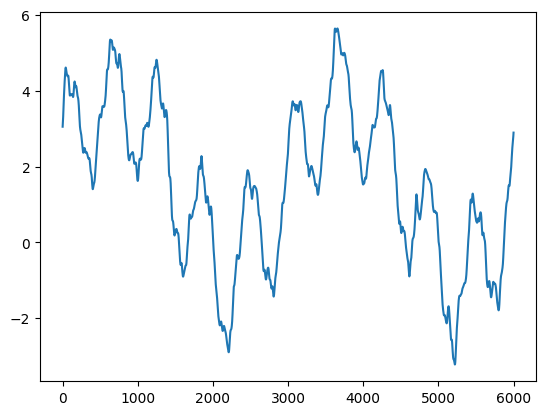

In [73]:
plt.plot(macro_arc + scene_arc + signals[0,:]/4 + signals[0,:]/4)